In [1]:
# Importando bibliotecas

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10,6)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# Download latest version
path = kagglehub.dataset_download("rohitgrewal/hr-data-mnc")

print("Path to dataset files:", path)

/kaggle/input/datasets/rohitgrewal/hr-data-mnc/HR_Data_MNC_Data Science Lovers.csv
Path to dataset files: /kaggle/input/datasets/rohitgrewal/hr-data-mnc


In [2]:
#ler CSV

df = pd.read_csv('/kaggle/input/datasets/rohitgrewal/hr-data-mnc/HR_Data_MNC_Data Science Lovers.csv')

df

,Unnamed: 0,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
0,0,EMP0000001,Joshua Nguyen,IT,Software Engineer,2011-08-10,"Isaacland, Denmark",5,14,Resigned,On-site,1585363
1,1,EMP0000002,Julie Williams,Marketing,SEO Specialist,2018-03-02,"Anthonyside, Costa Rica",2,7,Active,On-site,847686
2,2,EMP0000003,Alyssa Martinez,HR,HR Manager,2023-03-20,"Port Christinaport, Saudi Arabia",1,2,Active,On-site,1430084
3,3,EMP0000004,Nicholas Valdez,IT,Software Engineer,2023-10-12,"Port Shelbychester, Antigua and Barbuda",1,1,Active,On-site,990689
4,4,EMP0000005,Joel Hendricks,Operations,Logistics Coordinator,2024-12-09,"Lake Kimberly, Palestinian Territory",5,0,Active,On-site,535082
...,...,...,...,...,...,...,...,...,...,...,...,...
1999995,1999995,EMP1999996,Cody Russell,Operations,Logistics Coordinator,2010-08-31,"Casefurt, Serbia",3,14,Active,Remote,657648
1999996,1999996,EMP1999997,Tracey Smith,IT,Software Engineer,2021-05-07,"Dannyport, Kuwait",3,4,Active,On-site,1030109
1999997,1999997,EMP1999998,Tracy Lee,Sales,Business Development Manager,2024-05-29,"Craighaven, Nigeria",5,1,Active,Remote,1313085
1999998,1999998,EMP1999999,Michael Roberson,IT,Software Engineer,2023-02-14,"Jonathanmouth, Djibouti",4,2,Retired,On-site,1479727


In [3]:
del df['Unnamed: 0']
df

,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
0,EMP0000001,Joshua Nguyen,IT,Software Engineer,2011-08-10,"Isaacland, Denmark",5,14,Resigned,On-site,1585363
1,EMP0000002,Julie Williams,Marketing,SEO Specialist,2018-03-02,"Anthonyside, Costa Rica",2,7,Active,On-site,847686
2,EMP0000003,Alyssa Martinez,HR,HR Manager,2023-03-20,"Port Christinaport, Saudi Arabia",1,2,Active,On-site,1430084
3,EMP0000004,Nicholas Valdez,IT,Software Engineer,2023-10-12,"Port Shelbychester, Antigua and Barbuda",1,1,Active,On-site,990689
4,EMP0000005,Joel Hendricks,Operations,Logistics Coordinator,2024-12-09,"Lake Kimberly, Palestinian Territory",5,0,Active,On-site,535082
...,...,...,...,...,...,...,...,...,...,...,...
1999995,EMP1999996,Cody Russell,Operations,Logistics Coordinator,2010-08-31,"Casefurt, Serbia",3,14,Active,Remote,657648
1999996,EMP1999997,Tracey Smith,IT,Software Engineer,2021-05-07,"Dannyport, Kuwait",3,4,Active,On-site,1030109
1999997,EMP1999998,Tracy Lee,Sales,Business Development Manager,2024-05-29,"Craighaven, Nigeria",5,1,Active,Remote,1313085
1999998,EMP1999999,Michael Roberson,IT,Software Engineer,2023-02-14,"Jonathanmouth, Djibouti",4,2,Retired,On-site,1479727


# Informações Gerais

In [4]:
df.describe()

,Performance_Rating,Experience_Years,Salary_INR
count,2.000000e+06,2.000000e+06,2.000000e+06
mean,3.000148e+00,5.010287e+00,8.968878e+05
std,1.413973e+00,3.608823e+00,4.026103e+05
min,1.000000e+00,0.000000e+00,3.000000e+05
25%,2.000000e+00,2.000000e+00,6.163460e+05
50%,3.000000e+00,5.000000e+00,8.110265e+05
75%,4.000000e+00,8.000000e+00,1.073745e+06
max,5.000000e+00,1.500000e+01,2.999976e+06


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000000 entries, 0 to 1999999
Data columns (total 11 columns):
 #   Column              Dtype 
---  ------              ----- 
 0   Employee_ID         object
 1   Full_Name           object
 2   Department          object
 3   Job_Title           object
 4   Hire_Date           object
 5   Location            object
 6   Performance_Rating  int64 
 7   Experience_Years    int64 
 8   Status              object
 9   Work_Mode           object
 10  Salary_INR          int64 
dtypes: int64(3), object(8)
memory usage: 167.8+ MB


# Verificar Dados Nulos

In [6]:
df.isnull().sum()

Employee_ID           0
Full_Name             0
Department            0
Job_Title             0
Hire_Date             0
Location              0
Performance_Rating    0
Experience_Years      0
Status                0
Work_Mode             0
Salary_INR            0
dtype: int64

In [7]:
#Verificando duplicados
df.duplicated().sum()

np.int64(0)

# Análises

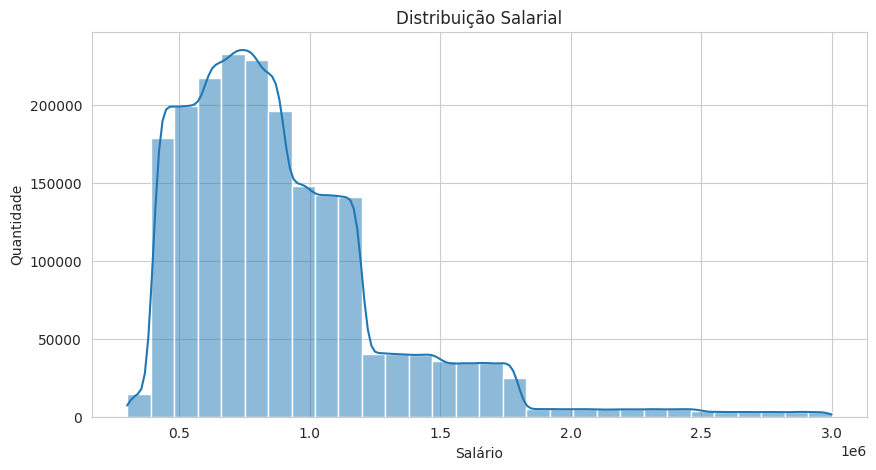

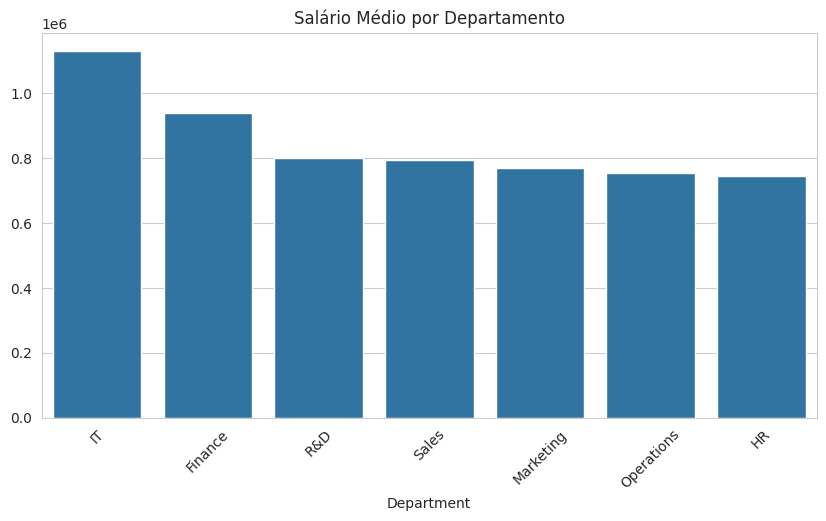

In [8]:
#Distribuição de Salários
plt.figure(figsize=(10,5))
sns.histplot(
    df['Salary_INR'],
    bins=30,
    kde=True
)
plt.title('Distribuição Salarial')
plt.xlabel('Salário')
plt.ylabel('Quantidade')
plt.show()

#Salário por Cargo
cargo_salario = (
    df.groupby('Job_Title')['Salary_INR'].mean().sort_values(ascending=False)
)
cargo_salario

#Qual departamento tem maior salario
depart_salary = (
    df.groupby('Department')['Salary_INR']
    .mean()
    .sort_values(ascending=False)
)
plt.figure(figsize=(10,5))

sns.barplot(
    x=depart_salary.index,
    y=depart_salary.values)
plt.xticks(rotation=45)
plt.title('Salário Médio por Departamento')
plt.show()

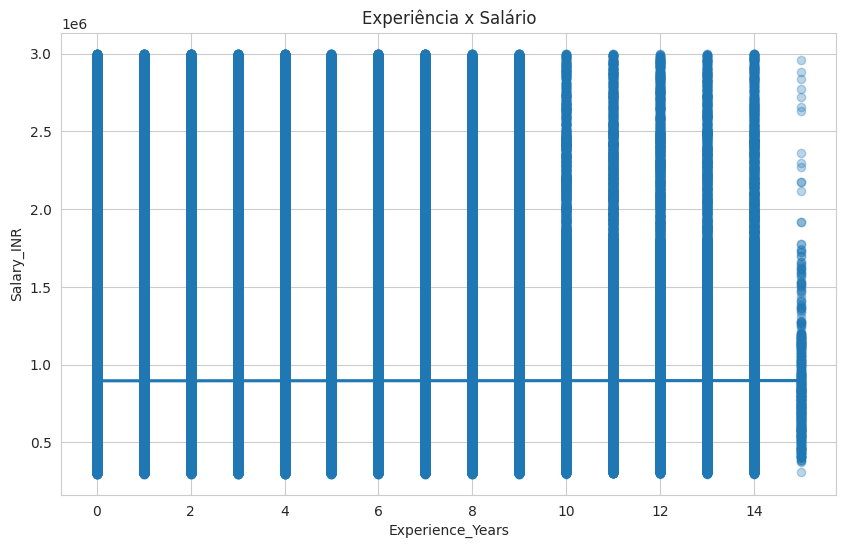

In [9]:
#Experiência influencia no salário
plt.figure(figsize=(10,6))
sns.regplot(
    data=df,
    x='Experience_Years',
    y='Salary_INR',
    scatter_kws={'alpha': 0.3}
)
plt.title('Experiência x Salário')
plt.show()

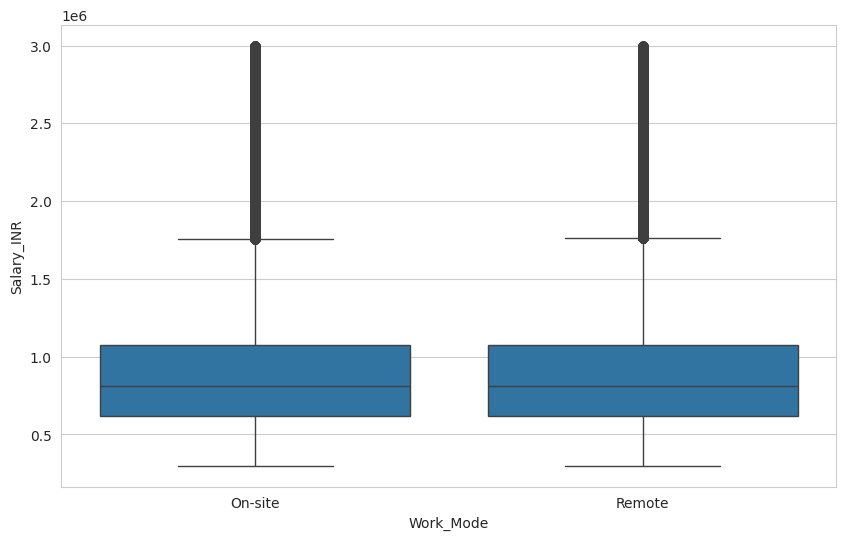

Status,Active,Resigned,Retired,Terminated
Department,,,,
Finance,69.902388,20.131784,4.968655,4.997173
HR,70.122361,19.944821,4.992490,4.940328
IT,70.100426,19.940703,4.987339,4.971533
Marketing,70.108005,19.907031,4.968323,5.016640
Operations,70.250421,19.792732,4.997084,4.959763
R&D,70.027767,19.967121,4.995038,5.010074
Sales,69.979077,19.929705,5.038110,5.053108


In [10]:
#Salário por modalidade
sns.boxplot(
    data=df,
    x='Work_Mode',
    y='Salary_INR'
)
plt.show()

#Situação do funcionário
pd.crosstab(
    df['Department'],
    df['Status'],
    normalize='index'
) * 100

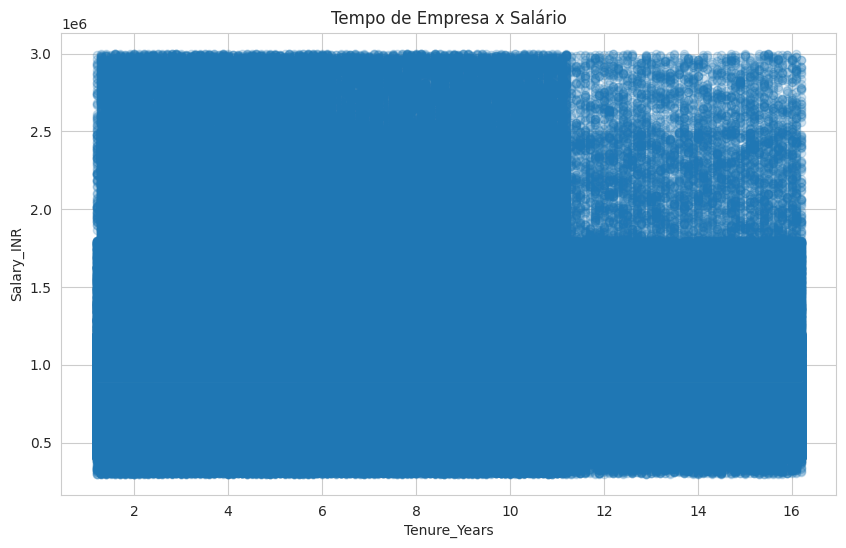

In [11]:
#Tempo de casa na empresa
df['Hire_Date'] = pd.to_datetime(df['Hire_Date'])
data_ref = pd.Timestamp.today()

df['Tenure_Years'] = (
    (data_ref - df['Hire_Date']).dt.days / 365.25
).round(1)

df[['Hire_Date', 'Tenure_Years']].head()

#temp de casa x salário
sns.regplot(
    data=df,
    x='Tenure_Years',
    y='Salary_INR',
    scatter_kws={'alpha':0.2}
)
plt.title('Tempo de Empresa x Salário')
plt.show()

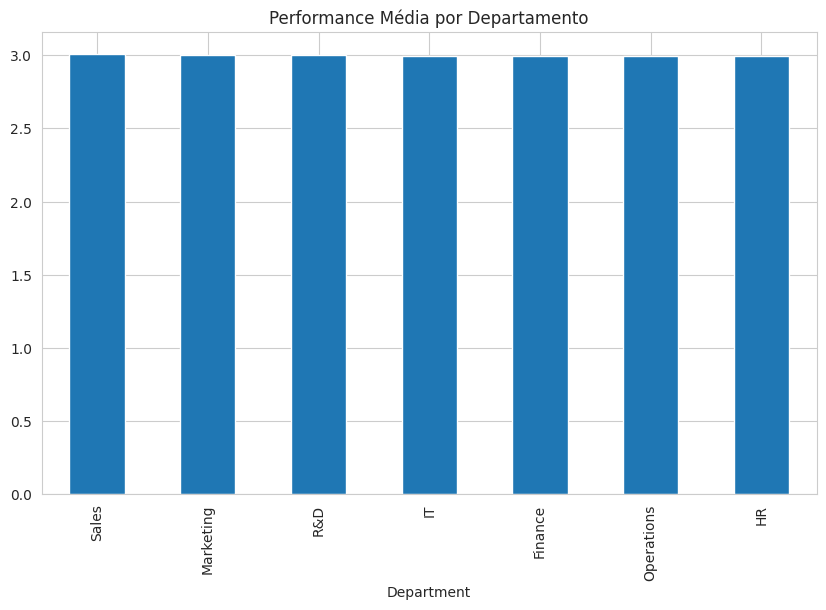

In [12]:
#qual departamento tem melhor desempenho
department_perf = (
    df.groupby('Department')['Performance_Rating']
    .mean()
    .sort_values(ascending=False)
)
department_perf.plot(kind='bar')
plt.title('Performance Média por Departamento')
plt.show()

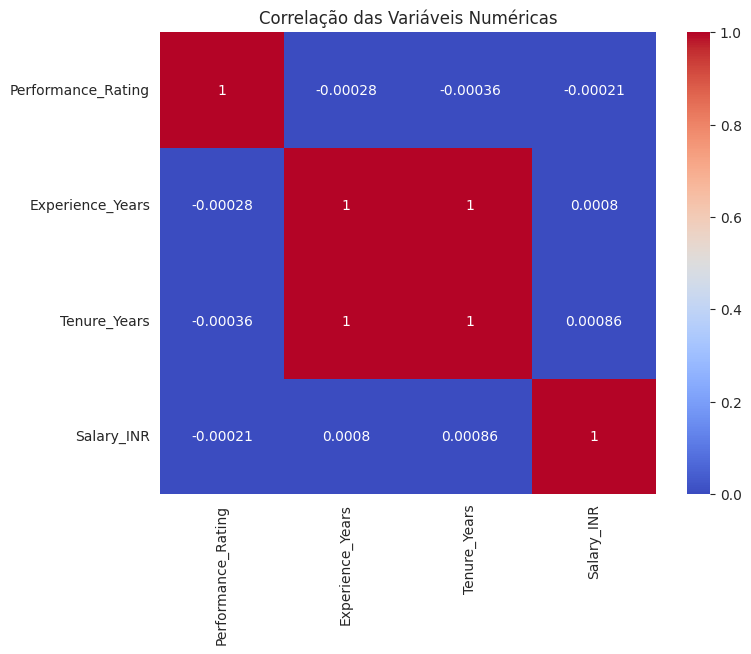

In [13]:
corr = df[
['Performance_Rating',
 'Experience_Years',
 'Tenure_Years',
 'Salary_INR']
].corr()

plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)
plt.title('Correlação das Variáveis Numéricas')
plt.show()

In [14]:
(df['Experience_Years'] - df['Tenure_Years']).describe()

count    2.000000e+06
mean    -1.718541e+00
std      2.909183e-01
min     -2.200000e+00
25%     -2.000000e+00
50%     -1.700000e+00
75%     -1.500000e+00
max     -1.200000e+00
dtype: float64

In [15]:
df.to_csv('/kaggle/working/hr_dataset.csv')


Insight 1

O departamento de TI apresentou a maior remuneração média da organização, seguido por Finanças.

Insight 2

Não foi observada correlação relevante entre salário e tempo de empresa.

Insight 3

A experiência profissional também não demonstrou associação significativa com a remuneração.

Insight 4

A distribuição salarial apresentou forte assimetria à direita, com poucos colaboradores concentrando salários muito elevados.

# BI

**1. Qual é a distribuição do status dos funcionários (Ativo, Pediu demissão, Aposentado, Demitido)?**

In [16]:
df['Status'].unique()

array(['Resigned', 'Active', 'Terminated', 'Retired'], dtype=object)

In [17]:
EmployeeActive = df[df['Status'] == 'Active'].groupby('Department').size().reset_index(name='Total_Active')
EmployeeActive

,Department,Total_Active
0,Finance,139716
1,HR,111578
2,IT,421333
3,Marketing,168316
4,Operations,210818
5,R&D,69859
6,Sales,279938


In [18]:
EmployeeRetired = df[df['Status'] == 'Retired'].groupby('Department').size().reset_index(name='Total_Retired')
EmployeeRetired

,Department,Total_Retired
0,Finance,9931
1,HR,7944
2,IT,29976
3,Marketing,11928
4,Operations,14996
5,R&D,4983
6,Sales,20154


In [19]:
EmployeeTerminated = df[df['Status'] == 'Terminated'].groupby('Department').size().reset_index(name='Total_Terminated')
EmployeeTerminated

,Department,Total_Terminated
0,Finance,9988
1,HR,7861
2,IT,29881
3,Marketing,12044
4,Operations,14884
5,R&D,4998
6,Sales,20214


In [20]:
EmployeeResigned = df[df['Status'] == 'Resigned'].groupby('Department').size().reset_index(name='Total_Resigned')
EmployeeResigned

,Department,Total_Resigned
0,Finance,40238
1,HR,31736
2,IT,119852
3,Marketing,47793
4,Operations,59397
5,R&D,19919
6,Sales,79725


**2. Qual é a distribuição dos modos de trabalho (presencial, remoto)?**

In [21]:
df['Work_Mode'].unique()

array(['On-site', 'Remote'], dtype=object)

In [22]:
WorkMode_OnSite = df[df['Work_Mode'] == 'On-site'].groupby('Department').size().reset_index(name='Total_OnSite')
WorkMode_OnSite

,Department,Total_OnSite
0,Finance,120155
1,HR,95133
2,IT,360222
3,Marketing,143743
4,Operations,180206
5,R&D,59774
6,Sales,239876


In [23]:
WorkMode_Remote = df[df['Work_Mode'] == 'Remote'].groupby('Department').size().reset_index(name='Total_Remote')
WorkMode_Remote

,Department,Total_Remote
0,Finance,79718
1,HR,63986
2,IT,240820
3,Marketing,96338
4,Operations,119889
5,R&D,39985
6,Sales,160155


**3. Quantos funcionários há em cada departamento?**

In [24]:
EmployeeActive

,Department,Total_Active
0,Finance,139716
1,HR,111578
2,IT,421333
3,Marketing,168316
4,Operations,210818
5,R&D,69859
6,Sales,279938


**4. Qual é o salário médio por departamento?**

In [25]:
SalaryMedian = df.groupby('Department')['Salary_INR'].median().reset_index(name='Salary Median')
SalaryMedian

,Department,Salary Median
0,Finance,805431.0
1,HR,680512.0
2,IT,1036675.0
3,Marketing,763590.0
4,Operations,737975.0
5,R&D,800964.0
6,Sales,743400.0


**5. Qual cargo tem o salário médio mais alto?**

In [26]:
HighSalary = df.groupby('Job_Title')['Salary_INR'].mean().sort_values(ascending=False).reset_index(name='Salary Average')
HighSalary.head(5).round(2)

,Job_Title,Salary Average
0,IT Manager,2098155.78
1,Finance Manager,1743241.53
2,HR Manager,1252401.91
3,Business Development Manager,1252016.23
4,Software Engineer,1199260.84


**6. Qual é o salário médio em diferentes departamentos com base no cargo?**

In [27]:
salario_depto_cargo = df.groupby(['Department', 'Job_Title'])['Salary_INR'].mean().reset_index(name='Salary_Average')

salario_depto_cargo = salario_depto_cargo.sort_values(by=['Department', 'Salary_Average'], ascending=[True, False])

salario_depto_cargo.round(2)

,Department,Job_Title,Salary_Average
2,Finance,Finance Manager,1743241.53
3,Finance,Financial Analyst,1051522.90
1,Finance,CFO,795015.87
0,Finance,Accountant,650076.48
6,HR,HR Manager,1252401.91
7,HR,Talent Acquisition Specialist,801422.24
4,HR,HR Director,800694.44
5,HR,HR Executive,550548.86
11,IT,IT Manager,2098155.78
12,IT,Software Engineer,1199260.84


**7. Como o salário varia com os anos de experiência?**

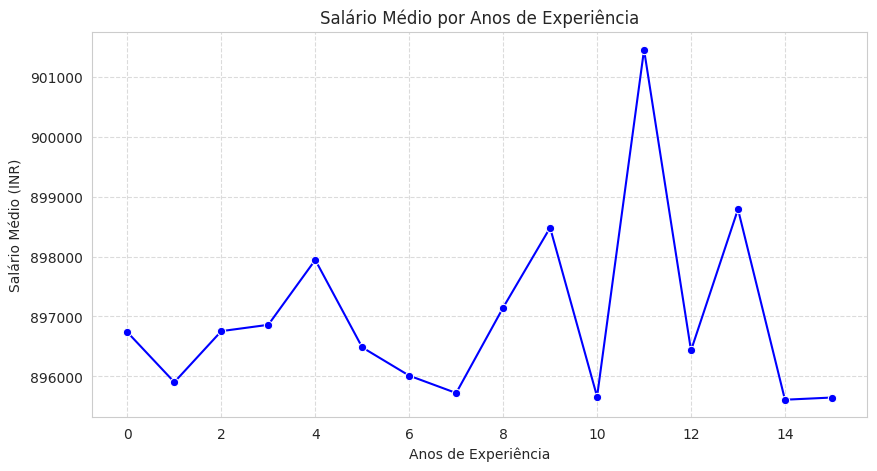

,Experience_Years,Salary_INR
0,0,896737.45
1,1,895903.76
2,2,896755.65
3,3,896861.25
4,4,897944.57
5,5,896484.08
6,6,896012.63
7,7,895722.67
8,8,897148.36
9,9,898482.94


In [28]:
# Agrupando por anos de experiência e calculando o salário médio
salario_por_experiencia = df.groupby('Experience_Years')['Salary_INR'].mean().reset_index()

# Criando um gráfico para visualizar a tendência
plt.figure(figsize=(10, 5))
sns.lineplot(data=salario_por_experiencia, x='Experience_Years', y='Salary_INR', marker='o', color='b')
plt.title('Salário Médio por Anos de Experiência')
plt.xlabel('Anos de Experiência')
plt.ylabel('Salário Médio (INR)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# Exibindo os valores numéricos
salario_por_experiencia.round(2)

**8. Qual é a classificação média de desempenho por departamento?**

In [29]:
# Calculando a classificação média de desempenho por departamento
desempenho_medio_depto = df.groupby('Department')['Performance_Rating'].mean().sort_values(ascending=False).reset_index(name='Performance_Average')

# Exibindo o resultado arredondado
desempenho_medio_depto.round(2)

,Department,Performance_Average
0,Sales,3.01
1,Marketing,3.00
2,R&D,3.00
3,IT,3.00
4,Finance,3.00
5,Operations,3.00
6,HR,3.00


**9. Qual país tem a maior concentração de funcionários?**

In [30]:
df['Country'] = df['Location'].apply(lambda x: x.split(',')[-1].strip() if pd.notnull(x) else None)

concentracao_paises = df['Country'].value_counts().reset_index(name='Employee_Count')

concentracao_paises.head(10)

,Country,Employee_Count
0,Congo,16286
1,Korea,16285
2,Sri Lanka,8409
3,Switzerland,8391
4,British Virgin Islands,8373
5,Iceland,8371
6,New Zealand,8347
7,Lesotho,8340
8,Peru,8327
9,Malaysia,8323


**10.  Identifique os departamentos com a maior taxa de rotatividade (Percentual de demissões).**

In [31]:
df['Turnover'] = df['Status'].isin(['Resigned', 'Terminated']).astype(int)

taxa_rotatividade = df.groupby('Department')['Turnover'].mean().reset_index(name='Turnover_Rate')
taxa_rotatividade['Turnover_Rate'] = (taxa_rotatividade['Turnover_Rate'] * 100).round(2)

taxa_rotatividade = taxa_rotatividade.sort_values(by='Turnover_Rate', ascending=False)

taxa_rotatividade

,Department,Turnover_Rate
0,Finance,25.13
5,R&D,24.98
6,Sales,24.98
3,Marketing,24.92
2,IT,24.91
1,HR,24.89
4,Operations,24.75
